# Workspace rental price tier prediction
**Sarthak Jain · 23f3000839 · MLP T3 2026**

This notebook contains the full CPU workflow for the registered competition notebook. The target is one of four price tiers. The earlier milestones established the data audit and preprocessing; here I compare a linear classifier, randomized trees and gradient boosting. I use a small set of model settings motivated by model capacity, rather than searching the leaderboard.

There is no external data, pretrained model, saved estimator or locally trained model in this notebook.

In [1]:
from pathlib import Path
import ast, json, time, platform, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from catboost import CatBoostClassifier

SEED = 173
np.random.seed(SEED)
OUT = Path("/kaggle/working")
OUT.mkdir(exist_ok=True)
roots = [
    p.parent
    for p in Path("/kaggle/input").rglob("train.csv")
    if (p.parent / "sample_submission.csv").exists()
    and (p.parent / "test.csv").exists()
]
assert len(roots) == 1, roots
DATA = roots[0]
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
assert set(train.price_tier.unique()) == {1, 2, 3, 4}
print("Python", platform.python_version(), "Train", train.shape, "Test", test.shape)
display(train.drop(columns=["facilities"]).head(3))


Python 3.13.15 Train (279746, 60) Test (114538, 59)


,space_id,operator_ref,operator_platform_age_years,operator_platform_age_months,operator_active_years,operator_active_months,operator_class,operator_certified,operator_portfolio_size,operator_has_avatar,...,score_access,score_value,compliance_status,operator_metro_units,operator_metro_whole,operator_metro_private,operator_metro_shared,reviews_per_month,metro,price_tier
0,0,Bralchu,12.0,8.0,7.0,8.0,independent_operator,f,2.0,t,...,9.12,9.54,unlicensed,2,0,2,0,0.42,MTR-09,2
1,1,Grorfian,2.0,2.0,2.0,2.0,independent_operator,f,3.0,t,...,NaN,NaN,unlicensed,3,1,2,0,NaN,MTR-01,1
2,2,Snelenr,10.0,10.0,7.0,10.0,independent_operator,f,1.0,t,...,10.00,10.00,unlicensed,1,1,0,0,0.03,MTR-01,2


## Data audit and exploratory analysis
Identifiers are excluded from predictors. I group identical raw predictor profiles before splitting so that duplicate copies cannot appear on both sides of validation. Numeric invalid-value checks, missingness and the target balance determine the preprocessing below. Coordinate values are retained as supplied; I do not assume that they represent real geographic locations.

Duplicate identifiers: 0
Duplicate predictor profiles: 1160


,dtype,missing_fraction
borough,object,0.766592
score_value,float64,0.193912
score_access,float64,0.193908
score_onboarding,float64,0.193901
score_accuracy,float64,0.193897
score_support,float64,0.193894
last_review_date,object,0.193890
score_condition,float64,0.193890
first_review_date,object,0.193890
reviews_per_month,float64,0.193890


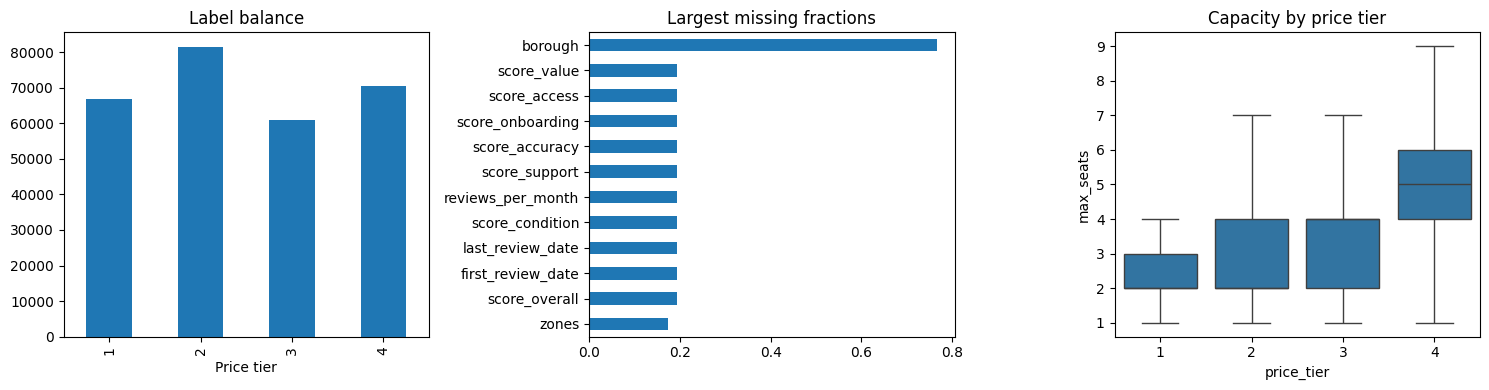

price_tier,1,2,3,4
metro,,,,
MTR-01,0.128,0.231,0.205,0.436
MTR-02,0.035,0.323,0.377,0.265
MTR-03,0.172,0.392,0.274,0.162
MTR-04,0.269,0.272,0.208,0.251
MTR-05,0.174,0.228,0.242,0.356
MTR-06,0.473,0.309,0.137,0.081
MTR-07,0.754,0.164,0.049,0.033
MTR-08,0.151,0.265,0.256,0.328
MTR-09,0.081,0.231,0.229,0.460


price_tier,1,2,3,4
space_class,,,,
Atrium Alcove,0.249,0.442,0.218,0.091
Atrium Bay,0.684,0.263,0.000,0.053
Atrium Floor,0.433,0.433,0.067,0.067
Atrium Quarter,0.000,0.250,0.000,0.750
Atrium Studio,0.382,0.471,0.088,0.059
Boutique Alcove,0.154,0.488,0.268,0.089
Boutique Bay,0.000,0.000,1.000,0.000
Boutique Gallery,0.000,0.000,0.000,1.000
Boutique Hub,0.000,0.500,0.000,0.500


price_tier,1,2,3,4
access_type,,,,
managed_suite,0.143,0.212,0.267,0.378
private_zone,0.454,0.349,0.124,0.073
shared_zone,0.849,0.097,0.024,0.029
whole_unit,0.168,0.276,0.248,0.308


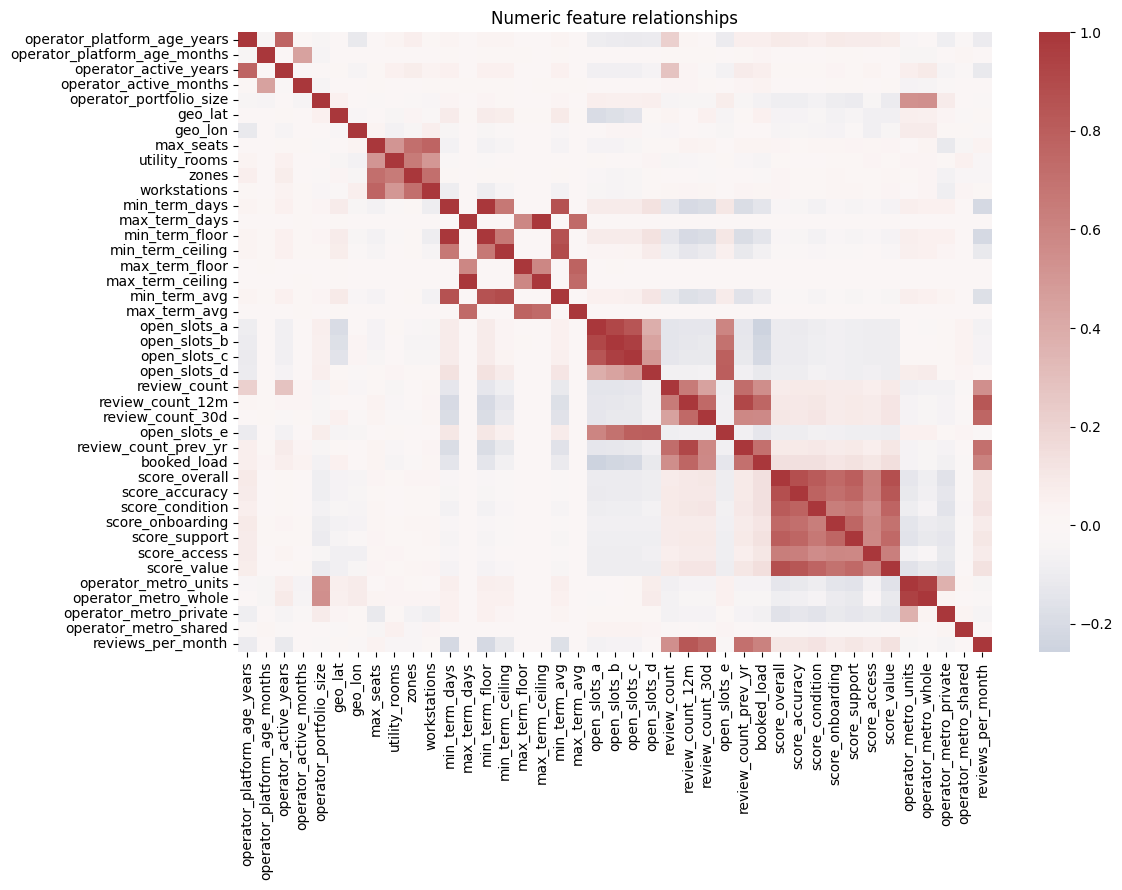

In [2]:
X = train.drop(columns="price_tier")
y = train.price_tier.astype(int)
print("Duplicate identifiers:", X.space_id.duplicated().sum())
print("Duplicate predictor profiles:", X.drop(columns="space_id").duplicated().sum())
display(
    pd.DataFrame(
        {"dtype": X.dtypes.astype(str), "missing_fraction": X.isna().mean()}
    ).sort_values("missing_fraction", ascending=False)
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y.value_counts().sort_index().plot.bar(ax=axes[0], title="Label balance")
axes[0].set_xlabel("Price tier")
X.isna().mean().nlargest(12).sort_values().plot.barh(
    ax=axes[1], title="Largest missing fractions"
)
sns.boxplot(data=train, x="price_tier", y="max_seats", showfliers=False, ax=axes[2])
axes[2].set_title("Capacity by price tier")
plt.tight_layout()
plt.savefig(OUT / "eda.png", dpi=150)
plt.show()
cat_cols = ["metro", "space_class", "access_type"]
for col in cat_cols:
    display(pd.crosstab(train[col], y, normalize="index").round(3).head(15))
num = train.select_dtypes("number").drop(columns=["space_id", "price_tier"])
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), cmap="vlag", center=0)
plt.title("Numeric feature relationships")
plt.tight_layout()
plt.savefig(OUT / "correlations.png", dpi=150)
plt.show()


## Split before learning preprocessing
A grouped, stratified split assigns about 70% to fitting, 10% to tuning and 20% to a final audit. Model settings and stopping rounds use only the tuning partition. The audit partition is evaluated after settings are frozen. These are random profile splits, so they estimate performance on similar listings rather than generalization to unseen operators or cities.

In [3]:
groups = pd.util.hash_pandas_object(X.drop(columns="space_id"), index=False)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, audit_idx = next(outer.split(X, y, groups))
inner = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=SEED + 1)
a, b = next(inner.split(X.iloc[dev_idx], y.iloc[dev_idx], groups.iloc[dev_idx]))
fit_idx, tune_idx = dev_idx[a], dev_idx[b]
for i, j in [(fit_idx, tune_idx), (fit_idx, audit_idx), (tune_idx, audit_idx)]:
    assert not set(groups.iloc[i]) & set(groups.iloc[j])
Xf, Xt, Xa = X.iloc[fit_idx], X.iloc[tune_idx], X.iloc[audit_idx]
yf, yt, ya = y.iloc[fit_idx], y.iloc[tune_idx], y.iloc[audit_idx]
split = pd.Series("fit", index=X.index)
split.iloc[tune_idx] = "tune"
split.iloc[audit_idx] = "audit"
pd.DataFrame(
    {"space_id": X.space_id, "partition": split, "profile_hash": groups}
).to_csv(OUT / "split.csv", index=False)
print(split.value_counts())
display(pd.crosstab(split, y, normalize="index"))


fit      195842
audit     55926
tune      27978
Name: count, dtype: int64


price_tier,1,2,3,4
row_0,,,,
audit,0.239030,0.290276,0.218324,0.252369
fit,0.239091,0.291475,0.217379,0.252055
tune,0.239367,0.293552,0.216492,0.250590


## Reusable preprocessing and feature engineering
The feature builder from my preprocessing milestone parses facility lists, derives date intervals, combines age fields and adds capacity ratios and missingness flags. Vocabulary and term caps are fitted only on fitting data. Nominal categories stay categorical for boosting; linear and tree baselines use imputation and one-hot encoding. Scaling is useful for the linear model, while tree splits do not need it.

In [4]:
M2_DATES = [
    "snapshot_start_date",
    "snapshot_end_date",
    "first_review_date",
    "last_review_date",
]
M2_FLAGS = [
    "operator_certified",
    "operator_has_avatar",
    "operator_id_verified",
    "bookable",
]
M2_CATS = [
    "metro",
    "borough",
    "zone",
    "space_class",
    "access_type",
    "operator_class",
    "compliance_status",
]
M2_TERMS = [
    "min_term_days",
    "max_term_days",
    "min_term_floor",
    "min_term_ceiling",
    "max_term_floor",
    "max_term_ceiling",
    "min_term_avg",
    "max_term_avg",
]
m2_num_cols = X.select_dtypes("number").columns.difference(["space_id"]).tolist()


def m2_clean_category(s):
    result = s.astype("string").str.strip()
    result = result.mask(result.eq(""))
    return result.astype(object).where(result.notna(), np.nan)


def m2_parse_facilities(value):
    if isinstance(value, list):
        obj = value
    elif pd.isna(value):
        return [], False
    else:
        try:
            obj = json.loads(value)
        except (ValueError, TypeError):
            try:
                obj = ast.literal_eval(str(value))
            except (ValueError, SyntaxError):
                return [], True
    if not isinstance(obj, list):
        return [], True
    if not all(isinstance(v, (str, int, float)) for v in obj):
        return [], True
    return sorted(set(str(v).strip() for v in obj if str(v).strip())), False


def m2_clean_numbers(frame):
    numbers = frame[m2_num_cols].apply(pd.to_numeric, errors="coerce").astype(float)
    numbers = numbers.replace([np.inf, -np.inf], np.nan)
    nonnegative = [c for c in numbers if c not in ["geo_lat", "geo_lon"]]
    numbers[nonnegative] = numbers[nonnegative].mask(numbers[nonnegative] < 0)
    scores = [c for c in numbers if c.startswith("score_")]
    numbers[scores] = numbers[scores].mask(numbers[scores] > 10)
    return numbers


class M2FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, facility_min_frequency=20, cap_quantile=0.995):
        self.facility_min_frequency = facility_min_frequency
        self.cap_quantile = cap_quantile

    def fit(self, X, y=None):
        self.caps_ = m2_clean_numbers(X)[M2_TERMS].quantile(self.cap_quantile)
        counts = Counter(
            v for values, bad in X.facilities.map(m2_parse_facilities) for v in values
        )
        self.facility_vocab_ = sorted(
            v for v, count in counts.items() if count >= self.facility_min_frequency
        )
        self.facility_index_ = {v: j for j, v in enumerate(self.facility_vocab_)}
        return self

    def transform(self, X):
        numeric = m2_clean_numbers(X)
        out = numeric.copy()
        for c in M2_TERMS:
            out[c + "_above_fit_cap"] = (numeric[c] > self.caps_[c]).astype("float32")
            out[c] = numeric[c].clip(upper=self.caps_[c])
        for c in numeric:
            if c not in ["geo_lat", "geo_lon"] and not c.startswith("score_"):
                out[c] = np.log1p(out[c])
        out["extreme_max_term"] = X.max_term_days.gt(36500).astype("float32")
        out["min_exceeds_max_term"] = X.min_term_days.gt(X.max_term_days).astype(
            "float32"
        )
        out["no_reviews"] = X.review_count.eq(0).astype("float32")
        out["platform_age_total_months"] = np.log1p(
            numeric.operator_platform_age_years * 12
            + numeric.operator_platform_age_months
        )
        out["active_age_total_months"] = np.log1p(
            numeric.operator_active_years * 12 + numeric.operator_active_months
        )
        out["log_seats_per_workstation"] = np.log1p(
            numeric.max_seats / numeric.workstations.replace(0, np.nan)
        )
        for c in M2_FLAGS:
            out[c] = (
                X[c]
                .astype("string")
                .str.strip()
                .str.lower()
                .map({"t": 1.0, "f": 0.0})
                .astype(float)
            )
        dates = {c: pd.to_datetime(X[c], errors="coerce") for c in M2_DATES}
        for c, d in dates.items():
            out[c + "_epoch_days"] = (
                d - pd.Timestamp("1970-01-01")
            ).dt.total_seconds() / 86400
        out["snapshot_year"] = dates["snapshot_start_date"].dt.year
        out["snapshot_month"] = dates["snapshot_start_date"].dt.month
        intervals = {
            "snapshot_span_days": ("snapshot_end_date", "snapshot_start_date"),
            "days_since_first_review": ("snapshot_start_date", "first_review_date"),
            "days_since_last_review": ("snapshot_start_date", "last_review_date"),
            "review_history_days": ("last_review_date", "first_review_date"),
        }
        for name, (end, start) in intervals.items():
            days = (dates[end] - dates[start]).dt.total_seconds() / 86400
            out[name] = np.sign(days) * np.log1p(days.abs())
            out[name + "_negative"] = days.lt(0).astype("float32")
        parsed = X.facilities.map(m2_parse_facilities)
        out["facility_count"] = np.log1p(parsed.map(lambda x: len(x[0])))
        out["facilities_malformed"] = parsed.map(lambda x: x[1]).astype("float32")
        out["facilities_missing"] = X.facilities.isna().astype("float32")
        hot = np.zeros((len(X), len(self.facility_vocab_)), dtype=np.float32)
        for i, (values, bad) in enumerate(parsed):
            for v in values:
                if v in self.facility_index_:
                    hot[i, self.facility_index_[v]] = 1.0
        hot_frame = pd.DataFrame(
            hot, index=X.index, columns=["facility__" + v for v in self.facility_vocab_]
        )
        out = pd.concat([out.astype("float32"), hot_frame], axis=1)
        for c in M2_CATS:
            out[c] = m2_clean_category(X[c])
        return out.replace([np.inf, -np.inf], np.nan)


features = M2FeatureBuilder().fit(Xf)
F = features.transform(Xf)
T = features.transform(Xt)
A = features.transform(Xa)
numeric = [c for c in F if c not in M2_CATS]
for frame in [F, T, A]:
    for c in M2_CATS:
        frame[c] = frame[c].fillna("__MISSING__").astype(str)
preprocess = ColumnTransformer(
    [
        (
            "numeric",
            Pipeline(
                [
                    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler()),
                ]
            ),
            numeric,
        ),
        (
            "category",
            OneHotEncoder(handle_unknown="ignore", min_frequency=20, dtype=np.float32),
            M2_CATS,
        ),
    ],
    sparse_threshold=1.0,
)
Zf = preprocess.fit_transform(F)
Zt = preprocess.transform(T)
print("Engineered matrix", F.shape, "Sparse baseline", Zf.shape)
assert "space_id" not in F and "operator_ref" not in F
print("Facility vocabulary learned on fit only:", len(features.facility_vocab_))


Engineered matrix (195842, 227) Sparse baseline (195842, 1165)
Facility vocabulary learned on fit only: 144


## Models and a limited tuning plan
The linear model checks whether additive effects are sufficient. Extra Trees adds nonlinear interactions without boosting. LightGBM uses sequential residual corrections; the second setting reduces leaf count and increases minimum leaf support to test whether regularization helps. CatBoost supplies a different treatment of categorical interactions. Boosting rounds are selected by early stopping on tuning data. Macro F1 gives each price tier equal weight.

In [5]:
rows = []
models = {}
preds = {}
fit_seconds = {}


def record(name, model, fit_data, tune_data, fit_kwargs=None):
    start = time.perf_counter()
    model.fit(fit_data, yf, **(fit_kwargs or {}))
    seconds = time.perf_counter() - start
    tr = model.predict(fit_data).reshape(-1).astype(int)
    p = model.predict(tune_data).reshape(-1).astype(int)
    row = dict(
        model=name,
        train_macro_f1=f1_score(yf, tr, average="macro"),
        tune_macro_f1=f1_score(yt, p, average="macro"),
        tune_accuracy=accuracy_score(yt, p),
        fit_seconds=seconds,
    )
    rows.append(row)
    models[name] = model
    preds[name] = p
    fit_seconds[name] = seconds
    pd.DataFrame(rows).to_csv(OUT / "model_comparison.csv", index=False)
    print(row, flush=True)


record(
    "linear_log_loss",
    SGDClassifier(
        loss="log_loss",
        alpha=1e-4,
        max_iter=1000,
        tol=1e-4,
        early_stopping=False,
        random_state=SEED,
        n_jobs=4,
    ),
    Zf,
    Zt,
)
record(
    "extra_trees",
    ExtraTreesClassifier(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=4,
        random_state=SEED,
    ),
    Zf,
    Zt,
)
# Categoricals share a fitting-only category vocabulary, including explicit missing.
cat_levels = {c: sorted(F[c].unique()) for c in M2_CATS}


def lgb_frame(frame, levels):
    out = frame.copy()
    for c in M2_CATS:
        out[c] = pd.Categorical(out[c], categories=levels[c])
    return out


Lf, Lt = lgb_frame(F, cat_levels), lgb_frame(T, cat_levels)


def macro_f1_metric(encoded_y, p):
    return "macro_f1", f1_score(encoded_y, p.argmax(axis=1), average="macro"), True


for name, leaves, child in [
    ("lightgbm_63", 63, 50),
    ("lightgbm_31_regularized", 31, 100),
]:
    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.04,
        num_leaves=leaves,
        min_child_samples=child,
        colsample_bytree=0.9,
        subsample=0.9,
        subsample_freq=1,
        reg_lambda=2.0,
        reg_alpha=0.1,
        random_state=SEED,
        n_jobs=4,
        verbosity=-1,
        metric="None",
    )
    record(
        name,
        model,
        Lf,
        Lt,
        dict(
            eval_set=[(Lt, yt)],
            eval_metric=macro_f1_metric,
            callbacks=[early_stopping(100), log_evaluation(200)],
        ),
    )


# Missing numerical values have an explicit sentinel; native strings remain categories.
def cb_frame(frame):
    out = frame.copy()
    out[numeric] = out[numeric].fillna(-999)
    return out


record(
    "catboost",
    CatBoostClassifier(
        iterations=1200,
        depth=7,
        learning_rate=0.06,
        loss_function="MultiClass",
        eval_metric="TotalF1:average=Macro",
        l2_leaf_reg=5,
        random_seed=SEED,
        thread_count=4,
        verbose=200,
        allow_writing_files=False,
    ),
    cb_frame(F),
    cb_frame(T),
    dict(
        cat_features=M2_CATS,
        eval_set=(cb_frame(T), yt),
        early_stopping_rounds=100,
        use_best_model=True,
    ),
)
comparison = pd.DataFrame(rows).sort_values("tune_macro_f1", ascending=False)
display(comparison)
winner = comparison.iloc[0].model
print("Frozen selection from tuning data:", winner)


{'model': 'linear_log_loss', 'train_macro_f1': 0.6301955308126872, 'tune_macro_f1': 0.6291786964399966, 'tune_accuracy': 0.6491886482236042, 'fit_seconds': 36.36529986099998}
{'model': 'extra_trees', 'train_macro_f1': 0.7470138150084641, 'tune_macro_f1': 0.6385703928961527, 'tune_accuracy': 0.658839087854743, 'fit_seconds': 259.38537575899994}
Training until validation scores don't improve for 100 rounds
[200]	valid_0's macro_f1: 0.713693
[400]	valid_0's macro_f1: 0.725351
[600]	valid_0's macro_f1: 0.7295
[800]	valid_0's macro_f1: 0.730486
[1000]	valid_0's macro_f1: 0.73254
[1200]	valid_0's macro_f1: 0.733529
[1400]	valid_0's macro_f1: 0.735009
[1600]	valid_0's macro_f1: 0.735299
Early stopping, best iteration is:
[1508]	valid_0's macro_f1: 0.735466
{'model': 'lightgbm_63', 'train_macro_f1': 0.9442966363399344, 'tune_macro_f1': 0.7354658461901837, 'tune_accuracy': 0.7389734791621989, 'fit_seconds': 373.813560358}
Training until validation scores don't improve for 100 rounds
[200]	valid

,model,train_macro_f1,tune_macro_f1,tune_accuracy,fit_seconds
2,lightgbm_63,0.944297,0.735466,0.738973,373.813560
3,lightgbm_31_regularized,0.865727,0.728382,0.732504,256.075738
4,catboost,0.751537,0.723772,0.727429,1890.625779
1,extra_trees,0.747014,0.638570,0.658839,259.385376
0,linear_log_loss,0.630196,0.629179,0.649189,36.365300


Frozen selection from tuning data: lightgbm_63


## Audit, model comparison and error analysis
The audit data was not used for stopping or model selection. Training versus tuning scores reveal overfitting; the audit measures how well the selected decision transfers. I report class-level recall and precision because an overall average can conceal failures on a particular tier. Permutation importance is a small diagnostic on the audit set, not another tuning input.

,model,train_macro_f1,tune_macro_f1,tune_accuracy,fit_seconds,audit_macro_f1,audit_accuracy
0,lightgbm_63,0.944297,0.735466,0.738973,373.813560,0.738081,0.741498
1,lightgbm_31_regularized,0.865727,0.728382,0.732504,256.075738,0.730702,0.734184
2,catboost,0.751537,0.723772,0.727429,1890.625779,0.723653,0.727300
3,extra_trees,0.747014,0.638570,0.658839,259.385376,0.641306,0.661589
4,linear_log_loss,0.630196,0.629179,0.649189,36.365300,0.627621,0.648571


              precision    recall  f1-score   support

           1     0.8338    0.8461    0.8399     13368
           2     0.6855    0.7336    0.7087     16234
           3     0.6176    0.5684    0.5920     12210
           4     0.8224    0.8013    0.8117     14114

    accuracy                         0.7415     55926
   macro avg     0.7398    0.7373    0.7381     55926
weighted avg     0.7407    0.7415    0.7406     55926



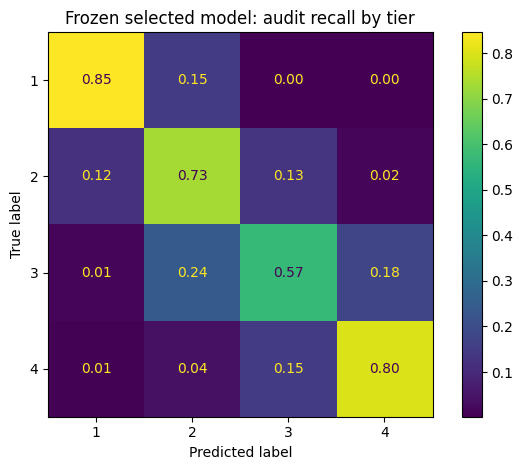

,count,error_rate
metro,,
MTR-12,3679,0.308508
MTR-02,4166,0.306289
MTR-10,5740,0.301568
MTR-04,2233,0.290640
MTR-13,2602,0.287855
MTR-03,2139,0.285180
MTR-16,3669,0.277187
MTR-08,2402,0.269359
MTR-15,2354,0.265506


,count,error_rate
space_class,,
Standard Hub,189,0.338624
Enclosed Alcove,326,0.325153
Central Berth,425,0.324706
Garden Pod,649,0.289676
Prime Loft,788,0.275381
Flex Bay,3764,0.275239
Standard Suite,321,0.267913
Atrium Alcove,568,0.265845
Elevated Suite,1685,0.265282


,space_id,metro,space_class,max_seats,review_count,truth,predicted,error
37,37,MTR-09,Premium Unit,2,0,1,2,True
69,69,MTR-16,Prime Quarter,10,139,4,3,True
92,92,MTR-03,Ground Bay,3,1,3,2,True
99,99,MTR-15,Ground Bay,4,0,4,3,True
101,101,MTR-14,Ground Bay,5,63,2,3,True
123,123,MTR-09,Boutique Workroom,1,287,1,2,True
130,130,MTR-13,Ground Bay,7,44,4,3,True
142,142,MTR-16,Flex Studio,6,0,3,4,True
150,150,MTR-04,Ground Bay,3,5,4,3,True
164,164,MTR-10,Ground Bay,2,29,3,2,True


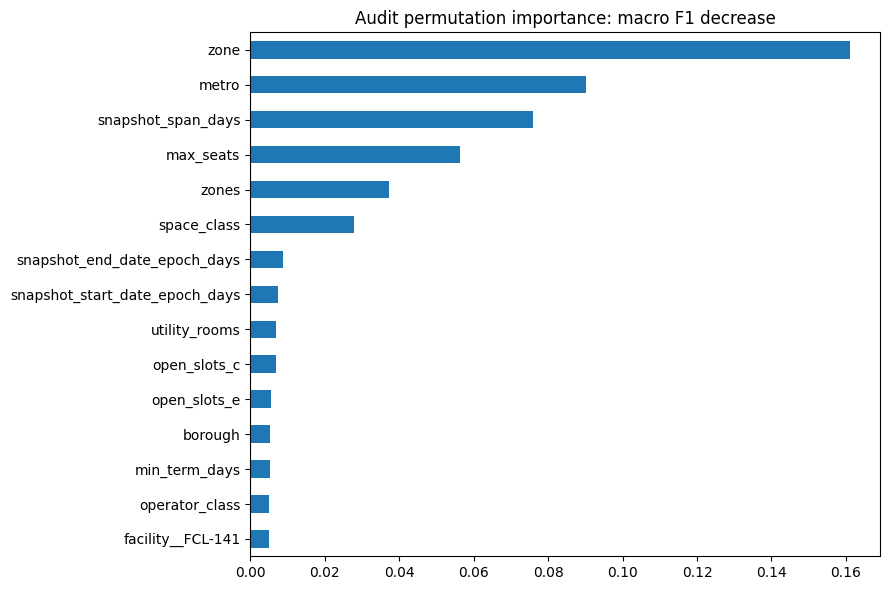

In [6]:
Za = preprocess.transform(A)
audit_rows = []
for name, model in models.items():
    if name.startswith("lightgbm"):
        matrix = lgb_frame(A, cat_levels)
    elif name == "catboost":
        matrix = cb_frame(A)
    else:
        matrix = Za
    p = model.predict(matrix).reshape(-1).astype(int)
    audit_rows.append(
        dict(
            model=name,
            audit_macro_f1=f1_score(ya, p, average="macro"),
            audit_accuracy=accuracy_score(ya, p),
        )
    )
    if name == winner:
        audit_pred = p
        audit_matrix = matrix
comparison = comparison.merge(pd.DataFrame(audit_rows), on="model")
comparison.to_csv(OUT / "model_comparison.csv", index=False)
display(comparison)
print(classification_report(ya, audit_pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    ya, audit_pred, normalize="true", values_format=".2f"
)
plt.title("Frozen selected model: audit recall by tier")
plt.tight_layout()
plt.savefig(OUT / "audit_confusion.png", dpi=150)
plt.show()
errors = Xa[["space_id", "metro", "space_class", "max_seats", "review_count"]].copy()
errors["truth"] = ya
errors["predicted"] = audit_pred
errors["error"] = errors.truth.ne(errors.predicted)
errors.to_csv(OUT / "audit_predictions.csv", index=False)
for col in ["metro", "space_class"]:
    display(
        errors.groupby(col, dropna=False)
        .agg(count=("error", "size"), error_rate=("error", "mean"))
        .query("count>=100")
        .sort_values("error_rate", ascending=False)
        .head(12)
    )
display(errors[errors.error].head(12))
if winner.startswith("lightgbm") or winner == "catboost":
    diag = audit_matrix.sample(n=min(2500, len(audit_matrix)), random_state=SEED)
    importance = permutation_importance(
        models[winner],
        diag,
        ya.loc[diag.index],
        scoring="f1_macro",
        n_repeats=2,
        random_state=SEED,
        n_jobs=1,
    )
    imp = pd.Series(importance.importances_mean, index=diag.columns).sort_values(
        ascending=False
    )
    imp.to_csv(OUT / "permutation_importance.csv")
    imp.head(15).sort_values().plot.barh(figsize=(9, 6))
    plt.title("Audit permutation importance: macro F1 decrease")
    plt.tight_layout()
    plt.savefig(OUT / "importance.png", dpi=150)
    plt.show()


## Final refit and submission
The winning family and stopping rounds are already frozen. Preprocessing is now fitted on all labelled rows, followed by model fitting on those rows. This is the first use of the test predictors. Predictions preserve the sample submission ID order. No estimator is imported or deserialized.

In [7]:
full_builder = M2FeatureBuilder().fit(X)
FX = full_builder.transform(X)
FT = full_builder.transform(test)
for frame in [FX, FT]:
    for c in M2_CATS:
        frame[c] = frame[c].fillna("__MISSING__").astype(str)
selected = models[winner]
if winner.startswith("lightgbm"):
    levels = {c: sorted(FX[c].unique()) for c in M2_CATS}
    p = selected.get_params()
    p["n_estimators"] = selected.best_iteration_ or p["n_estimators"]
    final = LGBMClassifier(**p)
    final.fit(lgb_frame(FX, levels), y)
    prediction = final.predict(lgb_frame(FT, levels))
elif winner == "catboost":
    p = selected.get_params()
    p["iterations"] = selected.tree_count_
    final = CatBoostClassifier(**p)
    final.fit(cb_frame(FX), y, cat_features=M2_CATS)
    prediction = final.predict(cb_frame(FT)).reshape(-1)
else:
    from sklearn.base import clone

    full_prep = clone(preprocess)
    final = clone(selected)
    final.fit(full_prep.fit_transform(FX), y)
    prediction = final.predict(full_prep.transform(FT))
submission = sample.copy()
assert submission.ID.equals(test.space_id)
submission["price_tier"] = np.asarray(prediction, dtype=int)
assert (
    len(submission) == len(test)
    and submission.price_tier.isin([1, 2, 3, 4]).all()
    and not submission.isna().any().any()
)
submission.to_csv(OUT / "submission.csv", index=False)
summary = {
    "selected_model": winner,
    "seed": SEED,
    "fit_rows": len(Xf),
    "tune_rows": len(Xt),
    "audit_rows": len(Xa),
    "full_train_rows": len(X),
    "test_rows": len(test),
    "selected_tune_macro_f1": float(
        comparison.set_index("model").loc[winner, "tune_macro_f1"]
    ),
    "selected_audit_macro_f1": float(
        comparison.set_index("model").loc[winner, "audit_macro_f1"]
    ),
    "cpu_only": True,
    "external_data": False,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
display(submission.head())
print(submission.price_tier.value_counts().sort_index())


{
  "selected_model": "lightgbm_63",
  "seed": 173,
  "fit_rows": 195842,
  "tune_rows": 27978,
  "audit_rows": 55926,
  "full_train_rows": 279746,
  "test_rows": 114538,
  "selected_tune_macro_f1": 0.7354658461901837,
  "selected_audit_macro_f1": 0.7380805366801599,
  "cpu_only": true,
  "external_data": false
}


,ID,price_tier
0,0,1
1,1,1
2,2,1
3,3,2
4,4,2


price_tier
1    26065
2    38625
3    22363
4    27485
Name: count, dtype: int64


## Interpretation and limits
Read the generated comparison table and audit confusion matrix before interpreting the final result. The final refit has no independent score of its own; only the executed competition submission produces a public leaderboard score. A profile split prevents exact-duplicate leakage but does not prove generalization to unseen operators. Future work should test an operator-disjoint split. The final model is chosen by tuning macro F1, not the leaderboard or the audit ranking.